# 05 – Phân lớp: đánh giá đặc trưng từ luật kết hợp
Đầu vào: `household_base.csv` (Bộ dữ liệu 1), `rule_features.csv` (notebook 04), `split.csv` (notebook 02).

| Bộ dữ liệu | Thuộc tính |
|---|---|
| D1 – gốc | 16 thuộc tính cấp hộ |
| D2 – gốc + Apriori | D1 + `ap_r1`, `ap_r2`, `ap_r3` |
| D3 – gốc + Multilevel | D1 + `ml_r1`, `ml_r2`, `ml_r3` |

Mô hình: Logistic Regression (LR), Decision Tree (DT), Random Forest (RF), cùng `class_weight='balanced'` vì lớp dương chỉ 27,4%. Tham số cố định cho cả 3 bộ dữ liệu để so sánh công bằng. Tất cả mô hình học trên **1.267 hộ train** và đánh giá **một lần** trên **317 hộ test** theo `split.csv`. Ngoài ra chạy 5-fold CV lặp 5 lần **trên tập train** để xem độ ổn định.

In [1]:
# Chạy trên Google Colab: kết nối Drive và chuyển vào thư mục notebooks của dự án (máy cá nhân thì bỏ qua)
import os
try:
    from google.colab import drive
    drive.mount('/content/drive')
    os.chdir('/content/drive/MyDrive/DM_Nhom3_Final/notebooks')  # sửa nếu để thư mục dự án ở chỗ khác
except ImportError:
    pass
print(os.getcwd())

/home/claude/DM_Nhom3_Final/notebooks


In [2]:
import sys, warnings
sys.path.append('../src'); warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix
from style import setup, save, vn, BLUE, ORANGE, AQUA, GRAY, INK, INK2
setup(); pd.set_option('display.width', 220)
SEED = 42

hb = pd.read_csv('../outputs/household_base.csv').set_index('household_key')
rf = pd.read_csv('../outputs/rule_features.csv').set_index('household_key')
split = pd.read_csv('../outputs/split.csv').set_index('household_key').set
y = hb.redeemed; base = [c for c in hb.columns if c != 'redeemed']
AP, ML = ['ap_r1','ap_r2','ap_r3'], ['ml_r1','ml_r2','ml_r3']
X = hb[base].join(rf)
DATASETS = {'D1 – gốc': base, 'D2 – gốc + Apriori': base + AP, 'D3 – gốc + Multilevel': base + ML}
tr, te = split.index[split=='train'], split.index[split=='test']
print('Train:', len(tr), f'(dương {y[tr].mean():.1%})  | Test:', len(te), f'(dương {y[te].mean():.1%})')

Train: 1267 (dương 27.4%)  | Test: 317 (dương 27.4%)


## 1. Mô hình và cách đánh giá

In [3]:
def models():
    return {'LR': make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, class_weight='balanced')),
            'DT': DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, class_weight='balanced', random_state=SEED),
            'RF': RandomForestClassifier(n_estimators=500, min_samples_leaf=3, class_weight='balanced', random_state=SEED, n_jobs=-1)}

rows, probs, fitted = [], {}, {}
for ds, cols in DATASETS.items():
    for m, mdl in models().items():
        mdl.fit(X.loc[tr, cols], y[tr]); p = mdl.predict_proba(X.loc[te, cols])[:, 1]; pred = (p >= 0.5).astype(int)
        probs[(ds, m)] = p; fitted[(ds, m)] = mdl
        rows.append({'Bộ dữ liệu': ds, 'Mô hình': m, 'Accuracy': accuracy_score(y[te], pred), 'Precision': precision_score(y[te], pred),
                     'Recall': recall_score(y[te], pred), 'F1': f1_score(y[te], pred), 'ROC-AUC': roc_auc_score(y[te], p)})
res = pd.DataFrame(rows)
res.to_csv('../outputs/ket_qua_phan_lop_test.csv', index=False)
res.round(4)

,Bộ dữ liệu,Mô hình,Accuracy,Precision,Recall,F1,ROC-AUC
0,D1 – gốc,LR,0.7161,0.4880,0.7011,0.5755,0.8003
1,D1 – gốc,DT,0.6909,0.4599,0.7241,0.5625,0.7689
2,D1 – gốc,RF,0.7192,0.4915,0.6667,0.5659,0.7799
3,D2 – gốc + Apriori,LR,0.7161,0.4882,0.7126,0.5794,0.8084
4,D2 – gốc + Apriori,DT,0.7350,0.5143,0.6207,0.5625,0.7731
5,D2 – gốc + Apriori,RF,0.7224,0.4956,0.6437,0.5600,0.7823
6,D3 – gốc + Multilevel,LR,0.7224,0.4961,0.7356,0.5926,0.8047
7,D3 – gốc + Multilevel,DT,0.6940,0.4597,0.6552,0.5403,0.7631
8,D3 – gốc + Multilevel,RF,0.7256,0.5000,0.6207,0.5538,0.7758


## 2. Độ ổn định: 5-fold CV lặp 5 lần trên tập train
Tập test chỉ có 317 hộ nên chênh lệch nhỏ giữa các bộ dữ liệu có thể do ngẫu nhiên. CV trên tập train cho biết mức dao động thông thường của ROC-AUC.

In [4]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
cv_rows = []
for ds, cols in DATASETS.items():
    for m, mdl in models().items():
        s = cross_val_score(mdl, X.loc[tr, cols], y[tr], cv=cv, scoring='roc_auc', n_jobs=-1)
        cv_rows.append({'Bộ dữ liệu': ds, 'Mô hình': m, 'AUC CV TB': s.mean(), 'AUC CV độ lệch chuẩn': s.std()})
cvres = pd.DataFrame(cv_rows)
cvres.to_csv('../outputs/ket_qua_phan_lop_cv.csv', index=False)
tab = res.merge(cvres, on=['Bộ dữ liệu','Mô hình'])
tab.pivot(index='Mô hình', columns='Bộ dữ liệu', values='AUC CV TB').round(4)

Bộ dữ liệu,D1 – gốc,D2 – gốc + Apriori,D3 – gốc + Multilevel
Mô hình,,,
DT,0.7310,0.7290,0.7435
LR,0.7913,0.7923,0.7976
RF,0.7776,0.7860,0.7957


In [5]:
# Mức thay đổi so với D1 (cùng mô hình)
d1 = tab[tab['Bộ dữ liệu']=='D1 – gốc'].set_index('Mô hình')
delta = tab[tab['Bộ dữ liệu']!='D1 – gốc'].copy()
for c in ['F1','ROC-AUC','AUC CV TB']:
    delta['Δ '+c] = delta[c].values - d1.loc[delta['Mô hình'], c].values
delta[['Bộ dữ liệu','Mô hình','Δ F1','Δ ROC-AUC','Δ AUC CV TB']].round(4)

,Bộ dữ liệu,Mô hình,Δ F1,Δ ROC-AUC,Δ AUC CV TB
3,D2 – gốc + Apriori,LR,0.0040,0.0080,0.0009
4,D2 – gốc + Apriori,DT,0.0000,0.0042,-0.0020
5,D2 – gốc + Apriori,RF,-0.0059,0.0024,0.0084
6,D3 – gốc + Multilevel,LR,0.0171,0.0044,0.0062
7,D3 – gốc + Multilevel,DT,-0.0222,-0.0058,0.0125
8,D3 – gốc + Multilevel,RF,-0.0120,-0.0040,0.0181


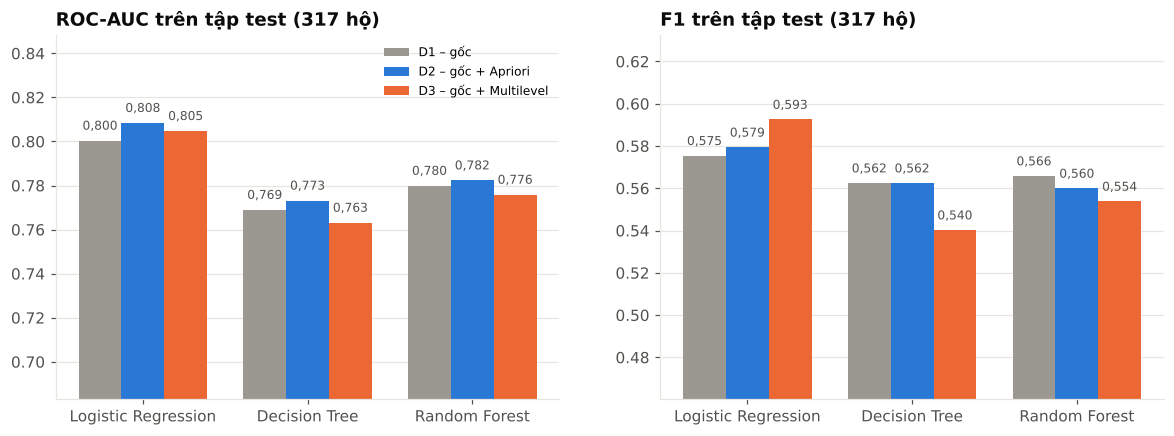

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3), sharey=False)
cols = {'D1 – gốc': GRAY, 'D2 – gốc + Apriori': BLUE, 'D3 – gốc + Multilevel': ORANGE}
x = np.arange(3); w = 0.26
for a, met in zip(ax, ['ROC-AUC', 'F1']):
    for k, ds in enumerate(DATASETS):
        v = res[res['Bộ dữ liệu']==ds].set_index('Mô hình').loc[['LR','DT','RF'], met]
        b = a.bar(x + (k-1)*w, v, w, color=cols[ds], label=ds)
        for r, val in zip(b, v): a.text(r.get_x()+r.get_width()/2, val+0.005, f'{val:.3f}'.replace('.',','), ha='center', fontsize=8, color=INK2)
    lo = res[met].min()
    a.set(ylim=(max(0, lo-0.08), res[met].max()+0.04), title=f'{met} trên tập test (317 hộ)'); a.set_xticks(x, ['Logistic Regression','Decision Tree','Random Forest'])
    a.grid(axis='x', visible=False)
ax[0].legend(loc='upper right', fontsize=8)
save(fig, 'H14_so_sanh_mo_hinh')

## 3. Đường ROC và ma trận nhầm lẫn của mô hình tốt nhất

Mô hình có ROC-AUC trung bình cao nhất: LR


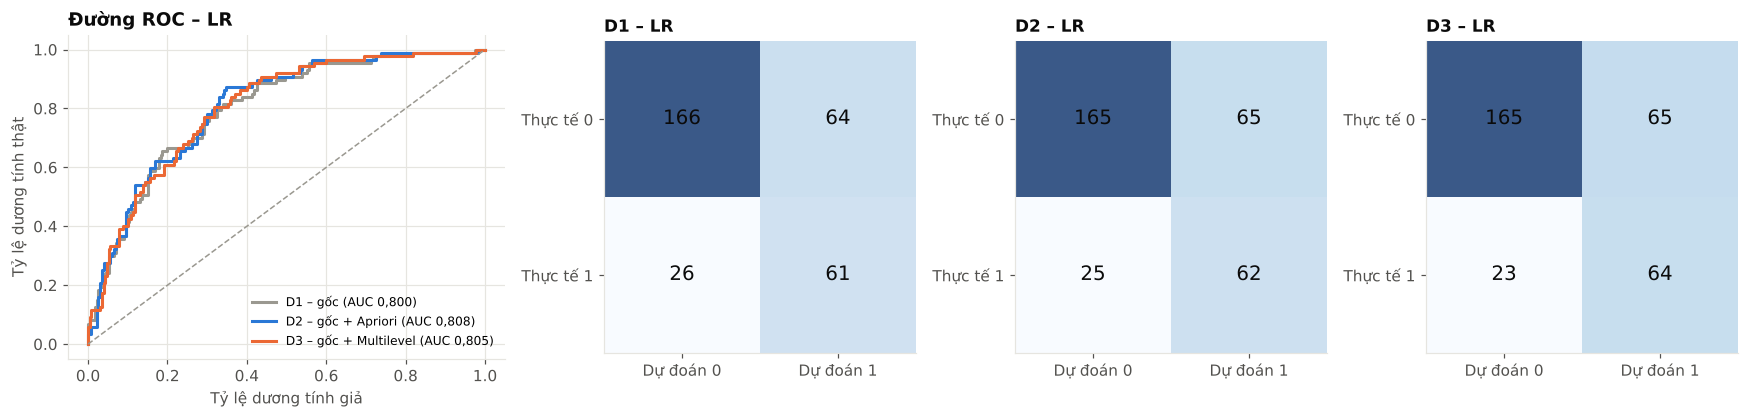

In [7]:
best_m = res.groupby('Mô hình')['ROC-AUC'].mean().idxmax(); print('Mô hình có ROC-AUC trung bình cao nhất:', best_m)
fig, ax = plt.subplots(1, 4, figsize=(16, 3.9), gridspec_kw={'width_ratios': [1.4, 1, 1, 1]})
for ds in DATASETS:
    f, t, _ = roc_curve(y[te], probs[(ds, best_m)])
    ax[0].plot(f, t, color=cols[ds], lw=2, label=f"{ds} (AUC {roc_auc_score(y[te], probs[(ds, best_m)]):.3f})".replace('.',','))
ax[0].plot([0,1],[0,1], ls='--', color=GRAY, lw=1); ax[0].set(xlabel='Tỷ lệ dương tính giả', ylabel='Tỷ lệ dương tính thật', title=f'Đường ROC – {best_m}')
ax[0].legend(loc='lower right', fontsize=8)
for a, ds in zip(ax[1:], DATASETS):
    cm = confusion_matrix(y[te], (probs[(ds, best_m)] >= .5).astype(int))
    a.imshow(cm, cmap='Blues', alpha=0.8); a.grid(False)
    for i in range(2):
        for j in range(2): a.text(j, i, cm[i, j], ha='center', va='center', fontsize=13, color=INK)
    a.set_xticks([0,1], ['Dự đoán 0','Dự đoán 1']); a.set_yticks([0,1], ['Thực tế 0','Thực tế 1']); a.set_title(ds.split(' – ')[0] + ' – ' + best_m, fontsize=11)
fig.tight_layout(); save(fig, 'H15_roc_ma_tran_nham_lan')

## 4. Đặc trưng từ luật đóng góp bao nhiêu?

In [8]:
imp = []
for ds in ['D2 – gốc + Apriori', 'D3 – gốc + Multilevel']:
    cols_ = DATASETS[ds]; r = fitted[(ds, 'RF')]
    s = pd.Series(r.feature_importances_, index=cols_).sort_values(ascending=False)
    lr = fitted[(ds, 'LR')][-1].coef_[0]
    for c in (AP if 'Apriori' in ds else ML):
        imp.append({'Bộ dữ liệu': ds, 'Đặc trưng': c, 'Hạng RF (/19)': int(s.index.get_loc(c)) + 1,
                    'Độ quan trọng RF': s[c], 'Hệ số LR (chuẩn hóa)': lr[cols_.index(c)]})
imp = pd.DataFrame(imp); imp.to_csv('../outputs/dong_gop_dac_trung_luat.csv', index=False); imp.round(4)

,Bộ dữ liệu,Đặc trưng,Hạng RF (/19),Độ quan trọng RF,Hệ số LR (chuẩn hóa)
0,D2 – gốc + Apriori,ap_r1,5,0.0656,0.2202
1,D2 – gốc + Apriori,ap_r2,8,0.0569,0.0796
2,D2 – gốc + Apriori,ap_r3,7,0.0609,0.1065
3,D3 – gốc + Multilevel,ml_r1,2,0.0940,0.4964
4,D3 – gốc + Multilevel,ml_r2,5,0.0682,-0.1153
5,D3 – gốc + Multilevel,ml_r3,12,0.0472,0.0952


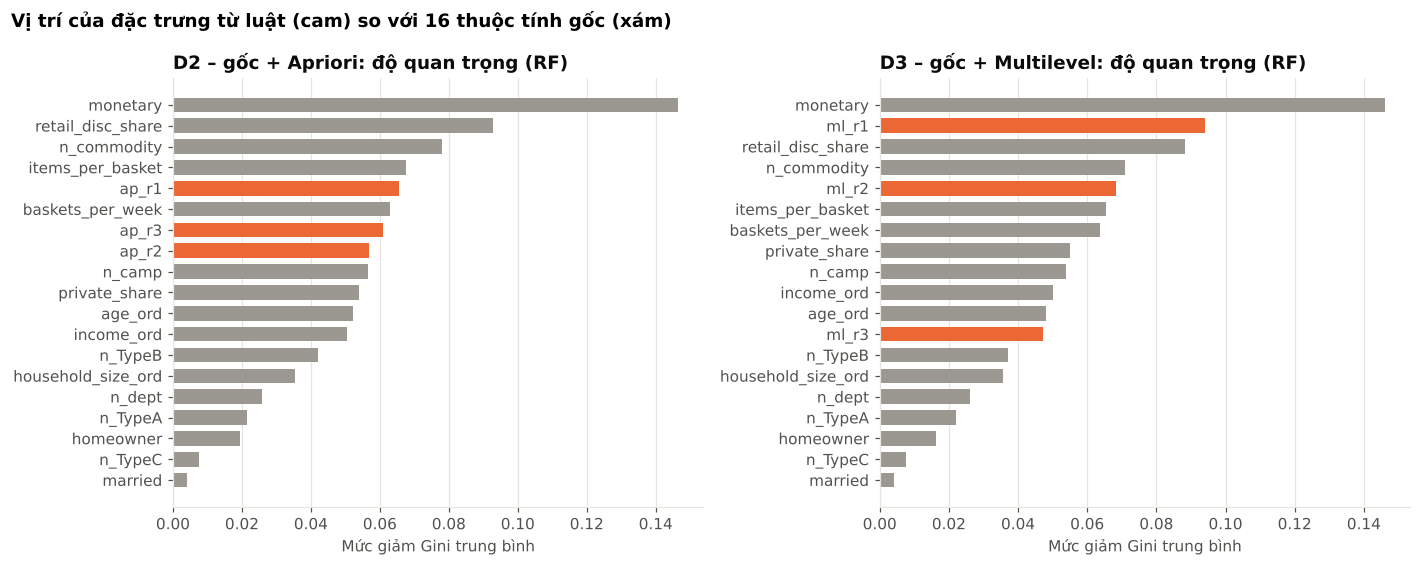

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))
for a, ds in zip(ax, ['D2 – gốc + Apriori', 'D3 – gốc + Multilevel']):
    cols_ = DATASETS[ds]; s = pd.Series(fitted[(ds,'RF')].feature_importances_, index=cols_).sort_values()
    a.barh(s.index, s.values, color=[ORANGE if c in AP+ML else GRAY for c in s.index], height=0.7)
    a.set(title=f'{ds}: độ quan trọng (RF)', xlabel='Mức giảm Gini trung bình'); a.grid(axis='y', visible=False)
fig.suptitle('Vị trí của đặc trưng từ luật (cam) so với 16 thuộc tính gốc (xám)', x=0.01, ha='left', fontweight='bold')
fig.tight_layout(); save(fig, 'H16_do_quan_trong_dac_trung')

## 5. Đối chứng: chọn luật theo lift thay vì theo mức liên quan với nhãn
Giữ nguyên mô hình, tham số và cách chia; chỉ thay 3 đặc trưng luật bằng 3 luật có lift cao nhất của từng phương pháp (`apL_*`, `mlL_*`). So sánh trên tập test và 5-fold CV lặp 5 lần trên tập train.

In [10]:
APL, MLL = ['apL_r1','apL_r2','apL_r3'], ['mlL_r1','mlL_r2','mlL_r3']
CONTRAST = {'D1 – gốc': base,
            'D2 – Apriori (liên quan y)': base + AP, 'D2L – Apriori (lift)': base + APL,
            'D3 – Multilevel (liên quan y)': base + ML, 'D3L – Multilevel (lift)': base + MLL}
rows = []
for ds, cols_ in CONTRAST.items():
    for m, mdl in models().items():
        mdl.fit(X.loc[tr, cols_], y[tr]); p = mdl.predict_proba(X.loc[te, cols_])[:, 1]
        s = cross_val_score(models()[m], X.loc[tr, cols_], y[tr], cv=cv, scoring='roc_auc', n_jobs=-1)
        rows.append({'Bộ dữ liệu': ds, 'Mô hình': m, 'ROC-AUC test': roc_auc_score(y[te], p),
                     'F1 test': f1_score(y[te], (p >= .5).astype(int)), 'AUC CV TB': s.mean(), 'AUC CV độ lệch chuẩn': s.std()})
con_tab = pd.DataFrame(rows)
con_tab.to_csv('../outputs/ket_qua_doi_chung_lift.csv', index=False)
con_tab.pivot(index='Bộ dữ liệu', columns='Mô hình', values='AUC CV TB').loc[list(CONTRAST)].round(4)

Mô hình,DT,LR,RF
Bộ dữ liệu,,,
D1 – gốc,0.7310,0.7913,0.7776
D2 – Apriori (liên quan y),0.7290,0.7923,0.7860
D2L – Apriori (lift),0.7409,0.7894,0.7872
D3 – Multilevel (liên quan y),0.7435,0.7976,0.7957
D3L – Multilevel (lift),0.7325,0.7896,0.7812


In [11]:
con_tab.pivot(index='Bộ dữ liệu', columns='Mô hình', values='ROC-AUC test').loc[list(CONTRAST)].round(4)

Mô hình,DT,LR,RF
Bộ dữ liệu,,,
D1 – gốc,0.7689,0.8003,0.7799
D2 – Apriori (liên quan y),0.7731,0.8084,0.7823
D2L – Apriori (lift),0.7580,0.7990,0.7824
D3 – Multilevel (liên quan y),0.7631,0.8047,0.7758
D3L – Multilevel (lift),0.7356,0.7986,0.7805


**Đầu ra:** `ket_qua_phan_lop_test.csv`, `ket_qua_phan_lop_cv.csv`, `dong_gop_dac_trung_luat.csv`, `ket_qua_doi_chung_lift.csv`, hình H14–H16.